# Time-step inspection
This notebook counts licit, illicit, and unknown training transactions at each time step. **This notebook helps see how to split validation set and choose models that can predict future transactions better.**

*It also shows where the future test transactions fall. It reads only `time_step` and `label` from training data, so it uses less memory than loading all 165 features.

**Labels:** `0` = licit, `1` = illicit, blank = unknown. Unknown labels are counted, not treated as licit.

## Time_Step Ranges in train.csv and test.csv

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FOLDER = "bt-4012-competition-2026"
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / DATA_FOLDER).is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(f"Open the notebook inside the project containing {DATA_FOLDER}.")
DATA = ROOT / DATA_FOLDER

train = pd.read_csv(DATA / "train.csv", usecols=["time_step", "label"])
test = pd.read_csv(DATA / "test.csv", usecols=["time_step"])
unexpected = train.loc[train.label.notna() & ~train.label.isin([0, 1]), "label"].unique()
if len(unexpected):
    raise ValueError(f"Unexpected known label values: {unexpected}")

print(f"Train: {len(train):,} transactions; time steps {train.time_step.min()}–{train.time_step.max()}")
print(f"Test: {len(test):,} transactions; time steps {test.time_step.min()}–{test.time_step.max()}")

Train: 141,772 transactions; time steps 1–35
Test: 15,329 transactions; time steps 36–49


## Counts by time step
`known_label_percent` tells you how much labelled data is available in a period. `illicit_among_known_percent` uses **only labelled transactions** as its denominator; it does not assume unknown transactions are licit.

In [2]:
train_step = train.groupby("time_step").agg(
    train_total=("label", "size"),
    known_labels=("label", "count"),
    illicit=("label", lambda s: int(s.eq(1).sum())),
    licit=("label", lambda s: int(s.eq(0).sum())),
)
train_step["unknown"] = train_step.train_total - train_step.known_labels
train_step["known_label_percent"] = (
    100 * train_step.known_labels / train_step.train_total
).round(1)
train_step["illicit_among_known_percent"] = (
    100 * train_step.illicit / train_step.known_labels
).round(1)
test_step = test.groupby("time_step").size().rename("test_total")
time_summary = train_step.join(test_step, how="outer").fillna(0)
count_columns = ["train_total", "known_labels", "licit", "illicit", "unknown", "test_total"]
time_summary[count_columns] = time_summary[count_columns].astype(int)
time_summary.index.name = "time_step"
display(time_summary)

print("Check: training rows accounted for:", time_summary.train_total.sum() == len(train))
print("Check: test rows accounted for:", time_summary.test_total.sum() == len(test))
print("Check: train labels accounted for:",
      (time_summary.licit + time_summary.illicit + time_summary.unknown).sum() == len(train))
print("Time steps shared by train and test:",
      sorted(set(train.time_step) & set(test.time_step)))

,train_total,known_labels,illicit,licit,unknown,known_label_percent,illicit_among_known_percent,test_total
time_step,,,,,,,,
1,7880,2147,17,2130,5733,27.2,0.8,0
2,4544,1117,18,1099,3427,24.6,1.6,0
3,6621,1279,11,1268,5342,19.3,0.9,0
4,5693,1440,30,1410,4253,25.3,2.1,0
5,6803,1882,8,1874,4921,27.7,0.4,0
6,4328,485,5,480,3843,11.2,1.0,0
7,6048,1203,102,1101,4845,19.9,8.5,0
8,4457,1165,67,1098,3292,26.1,5.8,0
9,4996,778,248,530,4218,15.6,31.9,0


Check: training rows accounted for: True
Check: test rows accounted for: True
Check: train labels accounted for: True
Time steps shared by train and test: []


## Visualize the time distribution for licit and illicit transactions inside `train.csv`
The first chart shows how many labelled and unlabelled training transactions occur in each period. 

The second shows the illicit share among **labels value** we already know inside the `train.csv`. Changes in this share may make future-period prediction harder.

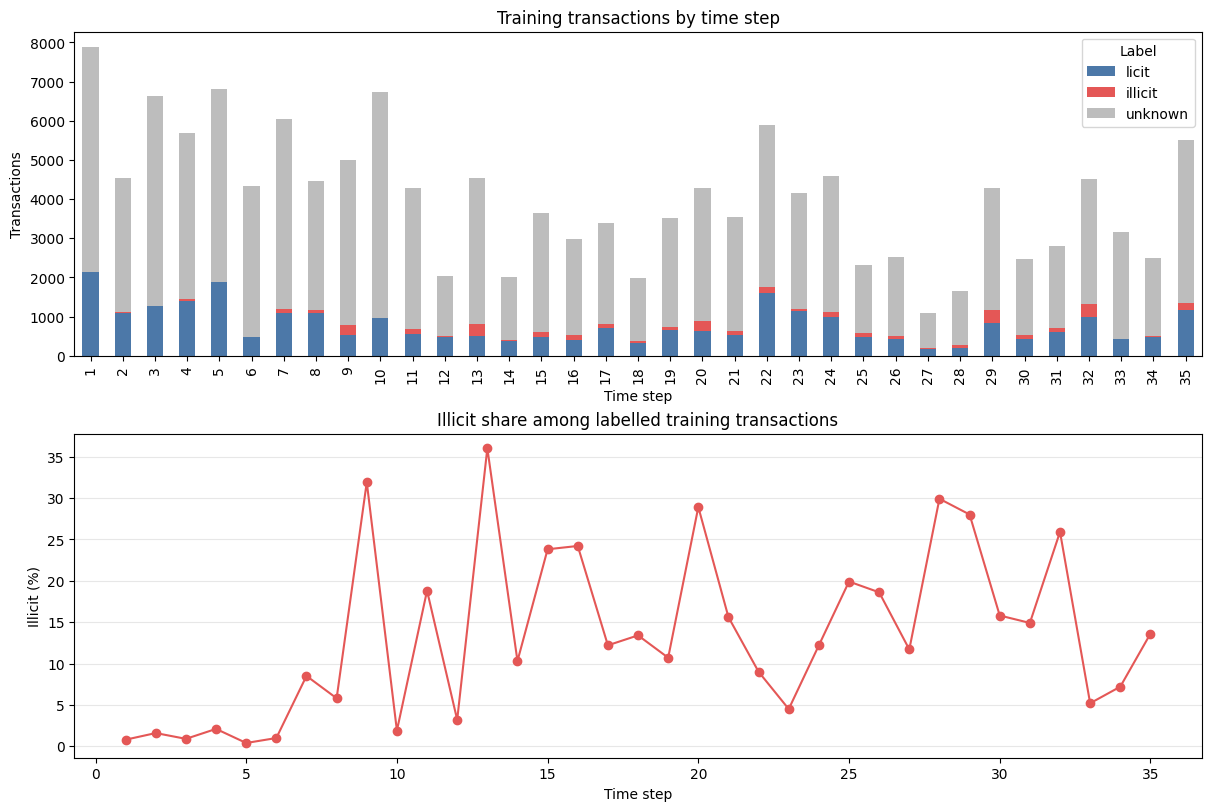

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)
train_step[["licit", "illicit", "unknown"]].plot.bar(
    stacked=True, ax=axes[0], color=["#4c78a8", "#e45756", "#bdbdbd"]
)
axes[0].set(title="Training transactions by time step", ylabel="Transactions", xlabel="Time step")
axes[0].legend(title="Label")
train_step["illicit_among_known_percent"].plot(
    ax=axes[1], marker="o", color="#e45756"
)
axes[1].set(title="Illicit share among labelled training transactions",
            ylabel="Illicit (%)", xlabel="Time step")
axes[1].grid(axis="y", alpha=0.3)
plt.show()

## Candidate chronological validation splits
These are **examples to evaluate**, not fixed requirements. Validation must use later time steps than its training portion. Only known labels contribute to model fitting and ROC-AUC. Check that validation has both classes.

### Some rules for the validation splits:
1. Time steps for validation set must be later than the train set
2. Both licit and illicit labels need to appear in validation set -> to see the ROC-AUC result

In [ ]:
splits = [
    ("earlier check", 1, 21, 22, 28),
    ("latest holdout", 1, 28, 29, 35),
]
rows = []
for name, train_start, train_end, val_start, val_end in splits:
    for portion, start, end in [("train", train_start, train_end),
                                ("validation", val_start, val_end)]:
        selected = train.loc[train.time_step.between(start, end), "label"]
        licit = int(selected.eq(0).sum())
        illicit = int(selected.eq(1).sum())
        rows.append({"split": name, "portion": portion,
                     "time_steps": f"{start}–{end}",
                     "all_transactions": len(selected),
                     "labelled": licit + illicit,
                     "licit": licit, "illicit": illicit,
                     "unknown_excluded_from_scoring": int(selected.isna().sum()),
                     "both_classes_present": licit > 0 and illicit > 0})
split_summary = pd.DataFrame(rows)
display(split_summary)
print("Test begins after the last training step:",
      test.time_step.min() > train.time_step.max())

,split,portion,time_steps,all_transactions,labelled,licit,illicit,unknown_excluded_from_scoring,both_classes_present
0,earlier check,train,1–21,94299,19530,17659,1871,74769,True
1,earlier check,validation,22–28,22230,5677,5006,671,16553,True
2,latest holdout,train,1–28,116529,25207,22665,2542,91322,True
3,latest holdout,validation,29–35,25243,6028,4926,1102,19215,True


Test begins after the last training step: True
